In [3]:
from matplotlib.colors import LogNorm
import seaborn as sns
import numpy as np
import pandas as pd
from utils import repeat
import matplotlib.pyplot as plt

In [6]:
df = pd.read_pickle("./data/keep/uniform_sparse_cs_Nov_2024.pickle")
print(df.columns)

Index(['sqt_n', 'm', 'sigma', 'lambda_', 'tol', 'img', 'sampling_type',
       'adapted_sampling', 'seed', 'rrep', 'runtime_seconds', 'fits', 'regs',
       'indices', 'experiment_fn_label', 'm_tld', 'emp_snr'],
      dtype='object')


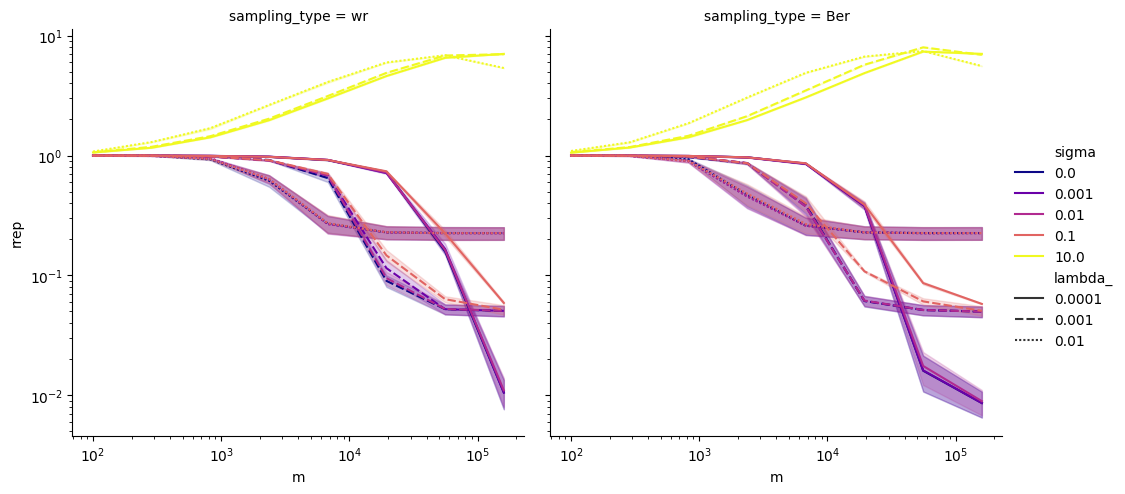

In [7]:
sns.relplot(df, kind = "line", x = "m", y = "rrep", col = "sampling_type", style = "lambda_", hue="sigma", hue_norm=LogNorm(vmin=1e-4, clip=True), palette="plasma", errorbar="se")
plt.xscale("log")
plt.yscale("log")

In [8]:
df = df[df['sigma'] < 1] # Exclude the noisy 10.

The main impacts come from:
1. Values of sigma for sigma above 0.01 (below that, effects are small).
2. Values of regularisation parameter lambda: small means better for small m, but worse for large m.
3. Less importantly, with-replacement vs Bernoulli; Bernoulli has a slight advantage.

Text(0.5, 1.0, 'Impact of the regularisation parameter lambda')

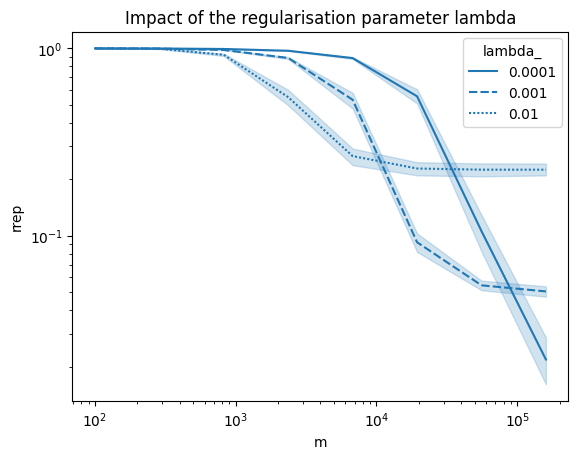

In [13]:
sns.lineplot(df, x="m", y="rrep", style="lambda_")
plt.xscale("log")
plt.yscale("log")
plt.title("Impact of the regularisation parameter lambda")

Text(0.5, 1.0, 'Advantage of Bernoulli sampling for uniform sampling.')

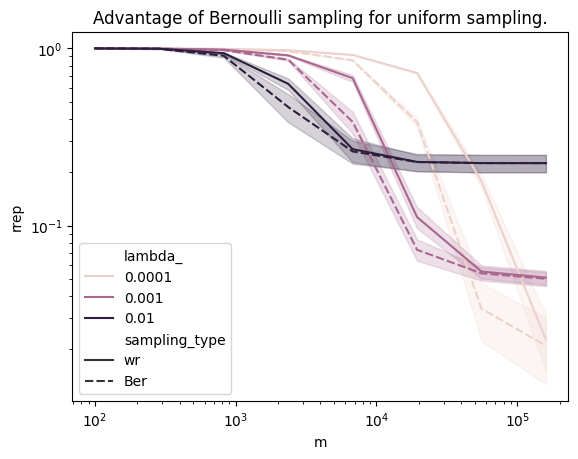

In [11]:
# slicedf=df[df['lambda_'] == 0.001]
sns.lineplot(df, x="m", y="rrep", style="sampling_type", hue="lambda_", hue_norm=LogNorm(vmin=1e-4, clip=True))
plt.xscale('log')
plt.yscale('log')
plt.title("Advantage of Bernoulli sampling for uniform sampling.")